# Why IC and MO1 / MO2 don't move together

Three 0DTE SPX iron condor books with **very similar setups**: all three sell 10-wide call and put spreads on SPX, expiring the same
day, one contract at a time, several entries a day. Yet in the backtester's portfolio view the IC strategy and the two MO books are
**almost uncorrelated**. This notebook works out why, and what it means for running them side by side.

**The short answer.**

1. **They mostly trade on different days.** IC trades 187 sessions and MO1 458, but **only 104 of them are the same day**. On a day
   only one of them trades, the other's P/L is zero, so that day adds swings to one book and nothing to the other. Most of MO1's ups and
   downs happen on days IC isn't trading.
2. **They trade on different days because their entry signals point opposite ways.** IC enters only on a **pullback** (SPX at or
   below its open); MO enters only when SPX is **stretched up** (at least 0.5% above its 5-day average). IC's other filters (its seven
   entry times, no Thursdays, the VIX9D/VIX band) remove more of MO's days.
3. **When they do trade the same minute, they're nearly the same trade** (condor P/L correlation 0.77). So the low correlation isn't
   the trades being different. It's **when** each one trades.
4. **Their big wins and losses come from different markets.** Each condor wins if SPX closes near where it was opened: IC's winning
   zone sits **below** the day's open (-0.53% to 0%), MO's **above** it (+0.13% to +0.39%). Up days hurt IC and pay MO; down days pay IC
   and hurt MO. IC sits out almost all the violent days MO trades, and the two never had a losing quarter at the same time.

**Contents.**

| § | question |
|---|---|
| 1 | The three books side by side |
| 2 | The correlation, measured like the backtester, and whether it ever spikes |
| 3 | Where the low correlation comes from: shared days, and how they move on them |
| 4 | Why they trade on different days: opposite entry signals |
| 5 | Shared days: why they still only move partly together; their worst days |
| 6 | **Why their spikes are different: what makes each one win and lose** |
| 7 | What running them together does: one portfolio, drawdowns, margin |
| 8 | Summary |

**How to read the numbers.**

- **Correlation is the backtester's portfolio correlation**: the correlation of daily P/L over every session, with days a book doesn't
  trade counted as zero.
- **IC is the strategy as traded** (`ic_analysis.ipynb`): no Thursdays, SPX at or below its open, SPX above its 10-day SMA, VIX9D/VIX
  0.87-1.02, seven entry times (11:33, 11:53, 12:13, 13:13, 13:53, 14:13, 14:53), short/long ratio <= 4, held to expiry with no stop.
  It is rebuilt from the 20-tranche export with the backtester's rules. **MO1 and MO2 are backtest logs** as exported.
- **Everything is on one calendar**: the 998 sessions the IC export covers, 2022-05-16 to 2026-05-07. The MO logs run to 2026-09;
  their trades after 2026-05-07 are left out so the three books are compared on the same days. MO1 starts trading 2022-05-25, MO2
  2022-06-21.
- **Sharpe is the backtester's** (daily P/L over $200k per book, less a 4% risk-free rate). Intervals are 95% session-bootstrap
  intervals.

## Setup

| file | what it is |
|---|---|
| `data/strategy/ic_strat/spx/raw_baseline/IC-20-Tranche-10-Baseline.csv` | the 20-tranche IC export the IC strategy is rebuilt from (see `ic_analysis.ipynb`) |
| `data/strategy/ic_strat/spx/mo/mo1.csv` | the MO1 backtest log: "IC 10w 35Delta - signal W (SPX>=0.5% over SMA5, 12:13-14:13)" |
| `data/strategy/ic_strat/spx/mo/mo2.csv` | the MO2 backtest log: "IC 10w 35Delta - signal W + Parkinson20 >= 8 (12:13-14:13)" |
| `data/market/vix/ohlc/` | 1-minute VIX9D and VIX, to measure IC's term-structure filter on MO's trades |

None of these are in git (`data/` is git-ignored).

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parents[2]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from strategies.ic_strat.analysis.ic_analysis import DEFAULT_CSV
from strategies.ic_strat.analysis import final_version as fv
from strategies.ic_strat.analysis import correlation_mo as cm
from strategies.ic_strat.analysis.notebook_display import compact_figures

compact_figures()   # charts as compact PNGs, so GitHub renders the notebook

study = fv.compute_final_study(DEFAULT_CSV)   # ~2 min: the IC strategy, rebuilt
books = cm.load_books(study)
print(f"{len(books.calendar)} sessions; condors: IC {len(books.ic):,}, MO1 {len(books.mo['MO1']):,}, MO2 {len(books.mo['MO2']):,}")

998 sessions; condors: IC 725, MO1 2,790, MO2 2,162


## 1. The three books side by side

,IC,MO1,MO2
condors,725,2790,2162
trades (spreads),1450,5580,4324
sessions traded,187,458,350
total_pl,112044.0,180572.8,186396.44
sharpe,2.59583,1.578353,1.85775
max_drawdown,-3808.68,-15704.2,-15704.2
win_rate_condor,80.965517,60.143369,61.748381
avg_pl_condor,154.543448,64.721434,86.21482
median_credit,325.0,470.0,480.0
median_short_call_pts,11.45,6.74,7.12


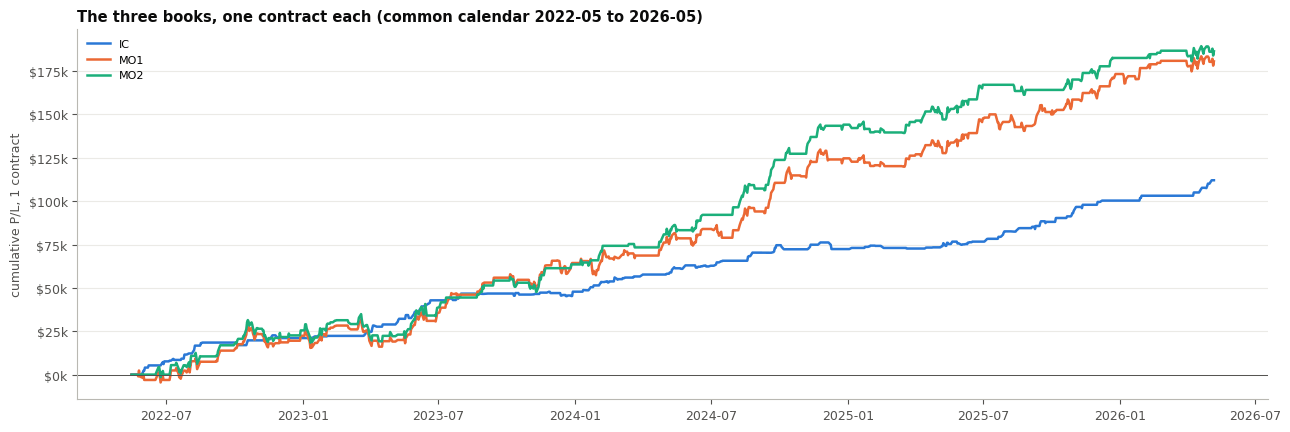

In [2]:
display(cm.setup_table(books))
cm.fig_equity(books); plt.show()

| | **IC** | **MO1** | **MO2** |
|---|---|---|---|
| structure | 10-wide iron condor, 0DTE SPX | same | same |
| short strikes | offsets from the export: median **11.5 pts** (call), **12.9 pts** (put) from spot | **35-delta**: median **6.7 / 6.9 pts** from spot | 35-delta: 7.1 / 7.3 pts |
| median credit | $325 | **$470** | $480 |
| entry times | **7: 11:33, 11:53, 12:13, 13:13, 13:53, 14:13, 14:53** | **12:13-14:13**, every 20 min | 12:13-14:13 |
| weekdays | Mon, Tue, Wed, Fri | **every weekday** | every weekday |
| entry signal | VIX9D/VIX 0.87-1.02, **SPX at or below its open**, SPX above its 10-day SMA, short/long <= 4 | **signal W: SPX >= 0.5% above its 5-day average** | signal W + Parkinson20 >= 8 |
| exit | held to expiry | held to expiry | held to expiry |
| condors (trades) | 725 (1,450) | 2,790 (5,580) | 2,162 (4,324) |
| sessions traded | 187 | 458 | 350 |
| total P/L | $112.0k | $180.6k | $186.4k |
| Sharpe | **2.60** | 1.58 | 1.86 |
| max drawdown | **-$3.8k** | -$15.7k | -$15.7k |
| win rate per condor | 81% | 60% | 62% |

- **Similar trades, different choices.** All three sell the same 10-wide condor on the same index on the same day. MO sells it **much
  closer to the money** (35 delta, about 7 points from spot, for $470 of credit against IC's $325 at 11-13 points), and MO decides
  *when* to trade with a different signal.
- **IC is the smaller, steadier book:** a quarter as many condors as MO1, a higher Sharpe, and a drawdown a quarter the size. MO makes more
  money at one contract each, with far bigger swings.
- **MO2 is MO1 with one more filter** (Parkinson20 >= 8, a realized-volatility floor): every MO2 trade is also an MO1 trade. That is why
  MO1 and MO2 behave as one book (below).

## 2. The correlation, measured like the backtester

Each pair's correlation of daily P/L (the backtester's measure), with its 95% interval, then the same on weekly and monthly P/L.
Right: the daily correlation over a trailing six months (126 sessions), to see whether it ever spikes.

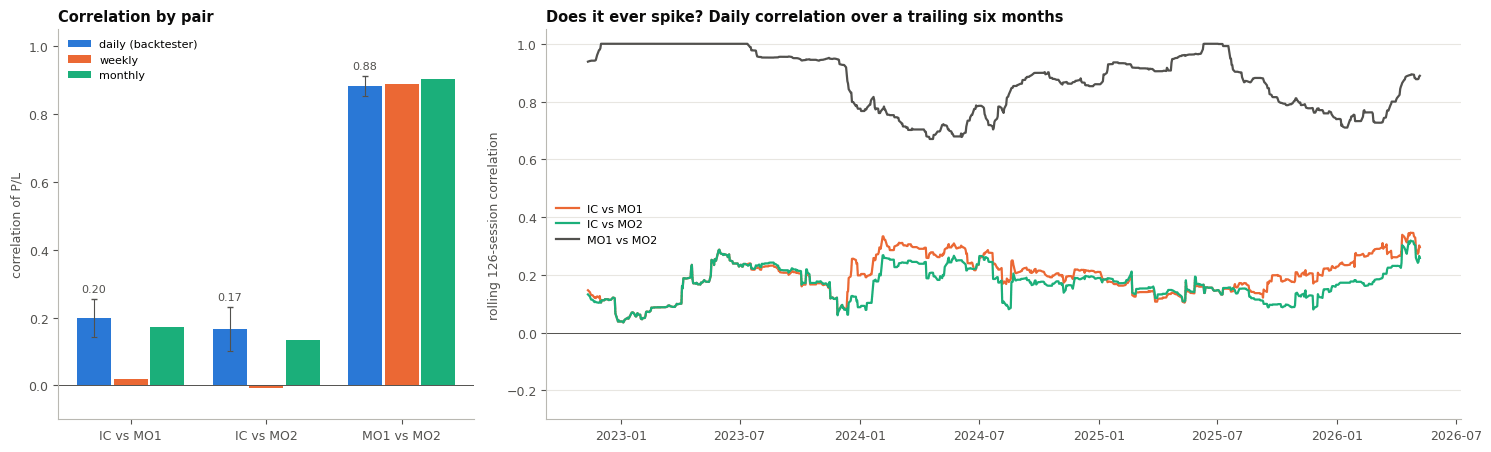

,daily,daily_ci_low,daily_ci_high,daily_rank (spearman),weekly,monthly
pair,,,,,,
IC vs MO1,0.199,0.142,0.256,0.160,0.018,0.171
IC vs MO2,0.165,0.101,0.231,0.123,-0.007,0.133
MO1 vs MO2,0.883,0.853,0.912,0.881,0.888,0.904


,IC vs MO1,IC vs MO2,MO1 vs MO2
count,873.00,873.00,873.00
mean,0.20,0.17,0.87
std,0.07,0.06,0.10
min,0.04,0.04,0.67
25%,0.15,0.13,0.78
50%,0.20,0.17,0.89
75%,0.24,0.22,0.96
max,0.35,0.32,1.00


In [3]:
ct = cm.correlation_table(books)
roll = cm.rolling_correlation(books)
cm.fig_correlation(books, ct, roll); plt.show()
display(ct.round(3))
display(roll.describe().round(2))

| pair | daily (backtester) | 95% interval | weekly | monthly | rolling 6-month range |
|---|---|---|---|---|---|
| **IC vs MO1** | **0.20** | 0.14 to 0.26 | 0.02 | 0.17 | 0.04 to 0.35 |
| **IC vs MO2** | **0.17** | 0.10 to 0.23 | -0.01 | 0.13 | 0.04 to 0.32 |
| MO1 vs MO2 | **0.88** | 0.85 to 0.91 | 0.89 | 0.90 | 0.67 to 1.00 |

- **IC is close to uncorrelated with both MO books**, on every time scale: -0.01 to 0.20, never above 0.35 in any six-month window.
- **MO1 and MO2 are close to the same book** (0.88, never below 0.67). The comparison shows that "similar setup" *can* mean high
  correlation: it depends on whether two books trade on the same days.
- **The correlation is small but not zero**, and the interval excludes zero. When IC and MO trade the same day they do tend to move
  together (§3), so the two books aren't independent, just mostly apart.

## 3. Where the low correlation comes from

A daily correlation has two ingredients: **how often both books trade on the same day**, and **how closely they move on those days**.
On a day only one book trades, the other's P/L is zero. That day adds to one book's swings (its variance) but adds nothing to how the
two move together (their covariance). So:

**correlation ~= (correlation on shared days) x sqrt(share of book A's variance on shared days x share of book B's)**

The table measures each part; the last two rows check the approximation against the actual correlation.

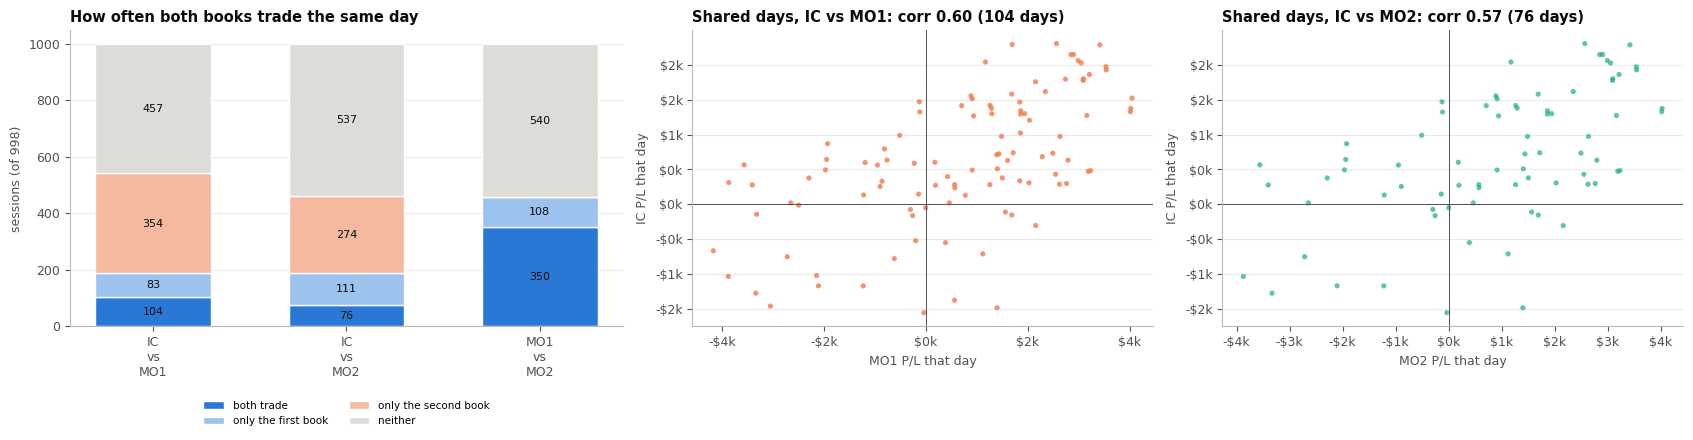

pair,IC vs MO1,IC vs MO2,MO1 vs MO2
days IC trades,187.000,187.000,NaN
days the other trades,458.000,350.000,350.000
days both trade,104.000,76.000,350.000
only the first,83.000,111.000,108.000
only the second,354.000,274.000,0.000
neither,457.000,537.000,540.000
corr on shared days,0.601,0.567,1.000
first's variance on shared days %,49.522,38.025,76.996
second's variance on shared days %,20.701,19.349,98.708
approx = shared corr x sqrt(shares),0.202,0.173,0.872


In [4]:
ov = cm.overlap_table(books)
cm.fig_overlap(books, ov); plt.show()
display(ov.round(3).T)

| | IC vs MO1 | IC vs MO2 | MO1 vs MO2 |
|---|---|---|---|
| sessions both trade | **104** | **76** | **350** |
| only the first / only the second | 83 / 354 | 111 / 274 | 108 / 0 |
| **correlation on shared days** | **0.60** | **0.57** | **1.00** |
| first book's variance that falls on shared days | **50%** | 38% | 77% |
| second book's variance that falls on shared days | **21%** | 19% | 99% |
| approximation: 0.60 x sqrt(0.50 x 0.21) | **0.20** | 0.17 | 0.87 |
| actual correlation | **0.20** | 0.17 | 0.88 |

**This is the whole explanation of the number.**

- **On the days they share, IC and MO1 do move together** (0.60). They're short the same SPX on the same afternoon.
- **But those days are a small part of MO1.** Half of IC's daily swings fall on shared days, but only 21% of MO1's: most of MO1's risk is
  taken on days IC is flat. Multiply it out (0.60 x sqrt(0.50 x 0.21)) and you get **0.20, the correlation the backtester shows**.
- **MO1 vs MO2 is the opposite case:** MO2 trades on 350 days, all of them MO1 days, with the same trades (shared-day correlation
  1.00). 99% of MO2's swings and 77% of MO1's happen on shared days, so the correlation stays at 0.88.

So the question "why aren't IC and MO correlated?" becomes "**why do they trade on different days?**".

## 4. Why they trade on different days: opposite entry signals

**MO's signal W** asks for SPX at least 0.5% **above** the average of its prior 5 closes: SPX has rallied and is stretched above its
recent level. **IC's max-move filter** asks for SPX **at or below** where it opened that morning: SPX has pulled back. Each dot below is
one condor, placed by those two measures at the moment it was opened.

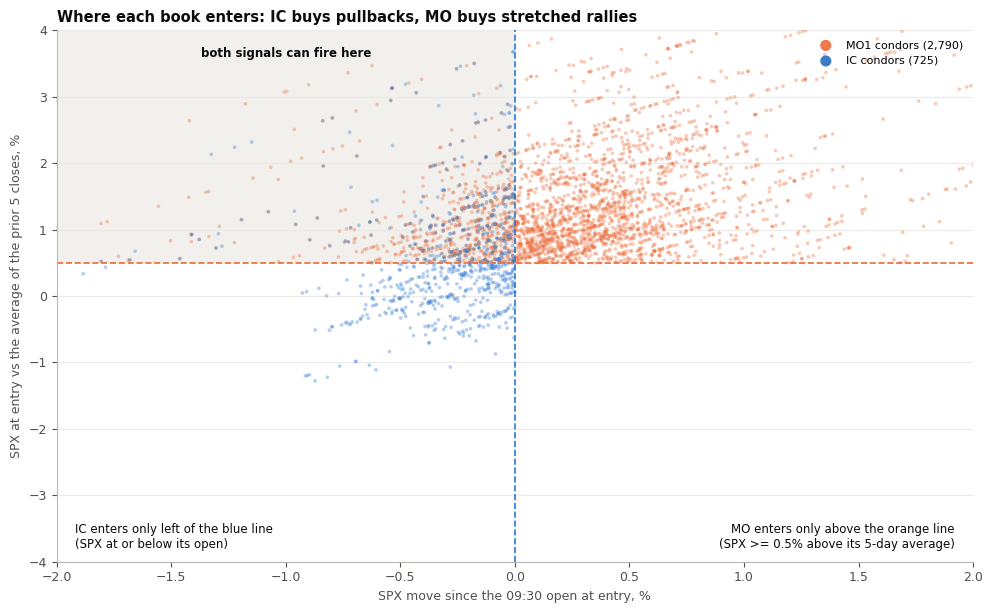

,IC,MO1,MO2
condors,725.0,2790.0,2162.0
SPX at/below its open (IC needs this) %,100.0,26.1,25.7
SPX >= 0.5% above SMA5 (MO needs this) %,44.6,100.0,100.0
both at once %,44.6,26.1,25.7
median move since open %,-0.2,0.3,0.3
median vs SMA5 %,0.4,1.1,1.3


,IC condors,pass signal W %,in MO's 12:13-14:13 window %,both %
0,725,44.6,57.5,25.5


In [5]:
cm.fig_signals(books); plt.show()
display(cm.signal_crosstab(books).round(1))
display(cm.w_on_ic(books).round(1))

| | IC condors | MO1 condors |
|---|---|---|
| SPX at or below its open at entry (IC's rule) | 100% | **26%** |
| SPX >= 0.5% above its 5-day average (MO's rule) | **45%** | 100% |
| median move since the open | **-0.2%** | **+0.3%** |
| median SPX vs its 5-day average | +0.4% | **+1.1%** |

- **The two rules pick opposite intraday moments.** MO enters on strength: its median entry is SPX 0.3% above the open and 1.1% above
  its 5-day average. IC enters on weakness: its median entry is 0.2% below the open.
- **They aren't mutually exclusive, which is why there is some overlap.** A day can be up over the week but down since the open (the
  shaded corner): 45% of IC's condors and a quarter of MO1's sit there. IC's 10-day SMA rule pulls it towards that corner: it only trades
  when SPX is above its recent average. Those are the shared days of §3.
- **The reverse is tight too:** only 26% of IC's condors are both signal-W entries and inside MO's 12:13-14:13 window.

The move filter isn't IC's only difference. MO1's condors put through IC's filters one at a time:

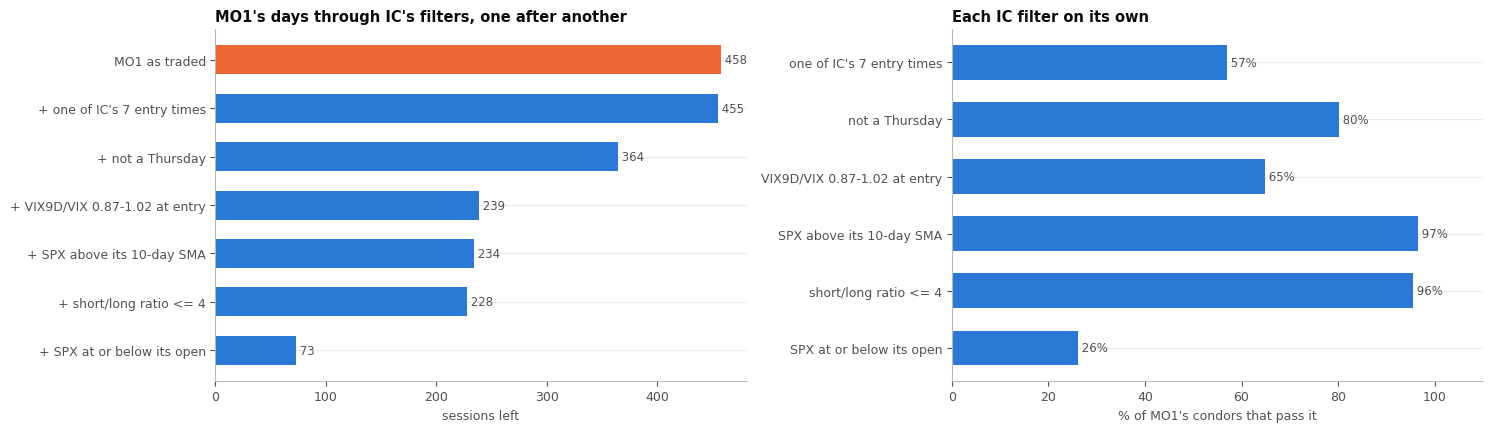

,condors left,sessions left,passes this filter alone %
filter,,,
MO1 as traded,2790,458,100.0
+ one of IC's 7 entry times,1591,455,57.0
+ not a Thursday,1280,364,80.1
+ VIX9D/VIX 0.87-1.02 at entry,814,239,64.8
+ SPX above its 10-day SMA,800,234,96.6
+ short/long ratio <= 4,740,228,95.6
+ SPX at or below its open,184,73,26.1


,condors left,sessions left,passes this filter alone %
filter,,,
MO2 as traded,2162,350,100.0
+ one of IC's 7 entry times,1235,350,57.1
+ not a Thursday,995,280,80.4
+ VIX9D/VIX 0.87-1.02 at entry,615,178,63.4
+ SPX above its 10-day SMA,603,174,96.0
+ short/long ratio <= 4,576,172,97.2
+ SPX at or below its open,135,54,25.7


In [6]:
fl1 = cm.ic_filters_on_mo(books, "MO1")
cm.fig_filters(fl1, "MO1"); plt.show()
display(fl1.round(1))
display(cm.ic_filters_on_mo(books, "MO2").round(1))

| MO1, through IC's filters | sessions left | condors left | share of MO1's condors that pass this filter on its own |
|---|---|---|---|
| MO1 as traded | 458 | 2,790 | |
| + **one of IC's 7 entry times** | 455 | 1,591 | 57% (12:13, 13:13, 13:53 and 14:13 are shared; 12:33, 12:53 and 13:33 aren't) |
| + **no Thursdays** | 364 | 1,280 | 80% |
| + **VIX9D/VIX 0.87-1.02 at entry** | 239 | 814 | 65% |
| + SPX above its 10-day SMA | 234 | 800 | 97% |
| + short/long ratio <= 4 | 228 | 740 | 96% |
| + **SPX at or below its open** | **73** | **184** | **26%** |

- **Only 73 of MO1's 458 days (and 7% of its condors) would pass every IC filter.** The rest are days IC can't trade.
- **The move filter does most of the separating:** on its own it rejects 74% of MO1's condors.
- **IC's entry times, no Thursdays and the VIX9D/VIX band each remove a large share too.** MO trades every 20 minutes from 12:13 to 14:13,
  trades Thursdays, and doesn't look at the term structure at all.
- **The trend filters barely differ:** 97% of MO1's condors already have SPX above its 10-day average, because a market 0.5% above its
  5-day average is almost always above its 10-day too. On trend, the two books agree; on **the intraday move**, they disagree.
- **MO2 is the same picture** (54 of its 350 days pass every IC filter).

## 5. Shared days: why they still only move partly together

On the 104 days both IC and MO1 trade, their daily P/L correlation is 0.60, not 1. Two things keep it there: they don't open at the
same minutes or at the same strikes, and they're picked for different reasons even on the same day.

In [7]:
for other in ("MO1", "MO2"):
    t = cm.shared_day_table(books, other)
    display(t.round(2))
    print(f"{other}: {t.attrs['shared_days']} shared days, {t.attrs['same_minute_entries']} same-minute entries; "
          f"both win on {t.attrs['both_win']} days, both lose on {t.attrs['both_lose']}; same sign on {t.attrs['sign_agree_pct']:.0f}%")
display(cm.same_minute_table(books, "MO1").round(2))

,IC,MO1
condors on shared days,404.00,628.00
condors a day,3.88,6.04
median move since open at entry %,-0.21,-0.06
median short-strike distance (pts),11.91,6.96
avg P/L per shared day,616.74,712.32


MO1: 104 shared days, 185 same-minute entries; both win on 61 days, both lose on 15; same sign on 73%


,IC,MO2
condors on shared days,294.00,471.00
condors a day,3.87,6.20
median move since open at entry %,-0.21,-0.06
median short-strike distance (pts),12.84,7.14
avg P/L per shared day,679.62,936.32


MO2: 76 shared days, 136 same-minute entries; both win on 47 days, both lose on 8; same sign on 72%


,value
same-minute pairs,185.00
condor P/L correlation,0.77
IC avg P/L,165.27
MO1 avg P/L,188.47
IC win rate %,81.08
MO1 win rate %,71.35
both win %,70.81
"IC wins, MO1 loses %",10.27
"MO1 wins, IC loses %",0.54
both lose %,18.38


**On a shared day, each book trades its own moments.** IC opens about 4 condors on such a day and MO1 about 6, and only 185 of IC's 404
condors on those days are at the same minute as an MO1 condor: IC enters when SPX dips below its open, at its seven times; MO1 at every
12:13-14:13 slot where SPX is stretched up.

**When they do open the same minute, they're nearly the same trade:**

| 185 same-minute pairs | IC | MO1 |
|---|---|---|
| condor P/L correlation | **0.77** | |
| median short strike from spot | 9.9 pts | 6.9 pts |
| average P/L | $165 | $188 |
| win rate | 81% | 71% |

| outcome of the same-minute pair | share |
|---|---|
| both win | 71% |
| IC wins, MO1 loses | **10%** |
| MO1 wins, IC loses | **0.5%** (one pair) |
| both lose | 18% |

- **The setups are similar, and it shows here:** at the same minute the two condors win and lose together (0.77).
- **The difference is strike distance.** At the same minute MO1's shorts sit 6.9 points from spot and IC's 9.9 (12 on average across
  IC's trades), so a move that breaks MO1's short strike can still leave IC's intact (10% of pairs), but almost never the reverse
  (one pair in 185). MO collects more ($470 against $325) for that extra risk.
- **By day:** on the 104 shared days the two books end with the same sign 73% of the time; IC wins while MO1 loses on 20 days, and MO1
  wins while IC loses on 8.

**Their worst days.** For each book, its worst 5% of trading days, and what the others did on those days:

In [8]:
display(cm.tail_table(books).round(1).T)

book,IC,MO1,MO2
worst days,10.0,23.0,18.0
its avg P/L on them,-1566.6,-4061.7,-3967.5
MO1: traded %,50.0,NaN,100.0
MO1: avg P/L,-444.8,NaN,-3967.5
MO1: lost too %,30.0,NaN,100.0
MO2: traded %,30.0,69.6,NaN
MO2: avg P/L,-196.8,-2803.6,NaN
MO2: lost too %,20.0,69.6,NaN
IC: traded %,NaN,17.4,11.1
IC: avg P/L,NaN,-36.1,-26.2


| | IC's 10 worst days (avg -$1,567) | MO1's 23 worst days (avg -$4,062) |
|---|---|---|
| IC traded / lost too | | traded on 17%, lost on **9%** (avg -$36) |
| MO1 traded / lost too | traded on 50%, lost on **30%** (avg -$445) | |
| MO2 traded / lost too | traded on 30%, lost on 20% | traded on 70%, lost on **70%** (avg -$2,804) |

- **Their bad days rarely line up.** On IC's 10 worst days MO1 lost on 3, and on MO1's 23 worst days IC lost on 2; on average the other
  book gave up only $36-445 on those days.
- **MO1 and MO2 share their bad days:** on MO1's worst days MO2 lost 70% of the time, and on MO2's worst days MO1 lost every time. That
  is what high correlation looks like in practice.

## 6. Why their spikes are different: what makes each one win and lose

Trading on different days explains the correlation number. It doesn't explain **why their big wins and big losses come from
different markets**. That comes from how a condor makes money: it keeps its credit if SPX closes between its short strikes, so
**each condor's winning zone is centred where SPX was when it was opened**. IC and MO open at different points of the day's path,
with different strike widths, so their winning zones sit in different places.

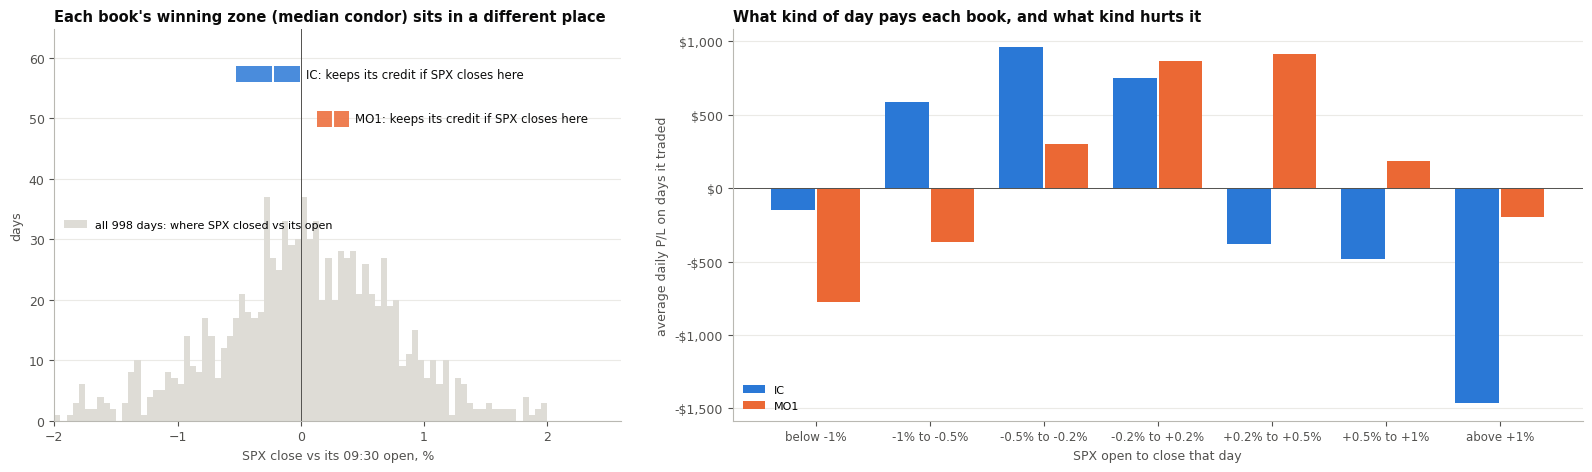

,short put (low edge),entry (centre),short call (high edge),width,"short strikes from spot, %"
IC,-0.53,-0.23,-0.00,0.46,0.21
MO1,0.13,0.26,0.39,0.25,0.13
MO2,0.14,0.29,0.43,0.27,0.14


IC vs MO1 median winning zones overlap by -0.14% (negative = they don't overlap)


IC          MO1          MO2        
               days avg P/L days avg P/L days avg P/L
day                                                  
below -1%         6  -151.0   11  -776.0    8  -439.0
-1% to -0.5%     30   590.0   26  -364.0   21  -119.0
-0.5% to -0.2%   53   961.0   56   302.0   41   485.0
-0.2% to +0.2%   74   750.0  117   868.0   83  1003.0
+0.2% to +0.5%   14  -380.0   78   912.0   60  1060.0
+0.5% to +1%      9  -484.0  111   184.0   84   348.0
above +1%         1 -1463.0   59  -194.0   53   -68.0

the same, on the days IC and MO1 both traded:


IC          MO1        
               days avg P/L days avg P/L
day                                     
below -1%         3  -125.0    3 -1476.0
-1% to -0.5%     13   705.0   13  -238.0
-0.5% to -0.2%   26  1152.0   26  1214.0
-0.2% to +0.2%   48   675.0   48  1120.0
+0.2% to +0.5%    8  -340.0    8  -191.0
+0.5% to +1%      5  -564.0    5   171.0
above +1%         1 -1463.0    1 -3047.0

In [9]:
zones = cm.profit_zone_table(books)
by_move = cm.pl_by_day_move(books)
cm.fig_spikes(books, zones, by_move); plt.show()
display(zones.round(2))
print(f"IC vs MO1 median winning zones overlap by {zones.attrs['ic_mo1_overlap']:+.2f}% (negative = they don't overlap)")
display(by_move.round(0))
print("the same, on the days IC and MO1 both traded:")
display(cm.pl_by_day_move(books, shared_only=True).round(0))

**1. Their winning zones don't overlap.** Measured against the day's 09:30 open, the median condor keeps its credit if SPX closes:

| | short put (low edge) | entry (centre) | short call (high edge) | width | short strikes from spot |
|---|---|---|---|---|---|
| **IC** | **-0.53%** | -0.23% | **0.00%** | 0.46% | 0.21% |
| **MO1** | **+0.13%** | +0.26% | **+0.39%** | 0.25% | 0.13% |

- **IC's zone sits below the open, MO's above it.** IC enters after a pullback (its median entry is 0.23% below the open), MO after a
  rally (0.26% above), and each condor is centred on its entry. The two median zones are 0.14% apart: **a close that keeps IC's credit
  in full sits outside MO's zone, and the other way round.**
- **MO's zone is about half as wide.** Its 35-delta shorts sit 0.13% from spot against IC's 0.21%, so MO needs SPX to finish closer to its
  entry. It collects more for that ($470 against $325).

**2. So different days pay each book, and different days hurt it.** Average daily P/L by how SPX moved from its open to its close, on
the days each book traded:

| SPX open to close | IC days | IC avg P/L | MO1 days | MO1 avg P/L |
|---|---|---|---|---|
| below -1% | 6 | -$151 | 11 | -$776 |
| -1% to -0.5% | 30 | **+$590** | 26 | **-$364** |
| -0.5% to -0.2% | 53 | **+$961** | 56 | +$302 |
| -0.2% to +0.2% | 74 | +$750 | 117 | +$868 |
| +0.2% to +0.5% | 14 | **-$380** | 78 | **+$912** |
| +0.5% to +1% | 9 | -$484 | 111 | +$184 |
| above +1% | 1 | -$1,463 | 59 | -$194 |

- **IC's best days are mild sell-offs** (-0.5% to -0.2%: +$961 a day); **its pain is up days** (+0.2% and above), where SPX runs away
  from a condor centred below the open, through its short call.
- **MO's best days are flat to mildly up** (-0.2% to +0.5%: +$868 to +$912); **its pain is down days** (-1% to -0.5% and worse), where SPX
  falls away from a condor centred above the open, through its short put.
- **The middle pays both** (-0.2% to +0.2%), and **only a big sell-off (below -1%) hurts both**, IC much less.
- **On the days they share** (second table) the down-day split holds: on a -1% to -0.5% day IC makes +$705 while MO1 loses $238. On the 8
  shared +0.2% to +0.5% days both lose a little (IC -$340, MO1 -$191).

In [10]:
display(cm.loss_sides(books).round(1))
display(cm.stress_table(books).round(0))

,losing condors,of them: call side broken %,put side broken %,worst 5%: put side broken %,traded days: median VIX at the open,traded days with VIX > 20 %,traded days: median range %,traded days that close below the open %
IC,138.0,54.3,45.7,48.6,16.0,19.3,0.8,68.4
MO1,1112.0,60.3,39.7,49.3,16.7,26.0,0.8,31.2
MO2,827.0,61.9,38.1,34.5,17.8,32.0,0.9,29.7


,days,IC traded,IC avg P/L when in,MO1 traded,MO1 avg P/L when in,MO2 traded,MO2 avg P/L when in,IC and MO1 both in,IC and MO2 both in
25 widest-range days,25.0,1.0,-1172.0,8.0,-339.0,8.0,-339.0,1.0,1.0
SPX fell > 1% open to close,91.0,6.0,-151.0,11.0,-776.0,8.0,-439.0,3.0,1.0
SPX rose > 1% open to close,86.0,1.0,-1463.0,59.0,-194.0,53.0,-68.0,1.0,0.0


**3. They're exposed to different markets.**

| | IC | MO1 |
|---|---|---|
| traded days that close below the open | **68%** | **31%** |
| traded days with VIX above 20 | 19% | **26%** |
| median VIX on traded days | 16.0 | 16.7 |

- **IC trades mostly down days, MO mostly up days.** 68% of IC's trading days close below their open, against 31% of MO1's. Each book's
  entry signal picks the kind of day it then trades.
- **IC is less exposed to stressed markets:** 19% of its trading days have VIX above 20, against 26% for MO1 (32% for MO2).

**4. On the market's worst days, they are almost never in together.**

| | days | IC in | MO1 in | MO2 in | IC and MO1 both in | IC and MO2 both in |
|---|---|---|---|---|---|---|
| the 25 widest-range days | 25 | 1 | 8 | 8 | **1** | **1** |
| SPX fell more than 1%, open to close | 91 | 6 | 11 | 8 | **3** | **1** |
| SPX rose more than 1%, open to close | 86 | 1 | 59 | 53 | **1** | **0** |

- **IC avoids almost all violent days.** It traded 1 of the 25 widest-range days and 6 of the 91 days SPX fell more than 1%.
- **MO trades strong up days, IC doesn't.** MO1 was in on 59 of the 86 days SPX rose more than 1% (losing only $194 a day on average,
  because its condor sits above the open), IC on 1.
- **The two were in together on 3 big down days and 1 big up day in four years**, and on 1 of the 25 widest-range days.

In [11]:
q = cm.quarterly_pl(books)
display(q.T.round(0))
jl = cm.joint_loss_days(books)
print(f"days both IC and MO1 lost: {len(jl)}")
display(jl.head(10).round(2))

date,2022Q2,2022Q3,2022Q4,2023Q1,2023Q2,2023Q3,2023Q4,2024Q1,2024Q2,2024Q3,2024Q4,2025Q1,2025Q2,2025Q3,2025Q4,2026Q1,2026Q2
IC,7629.0,10839.0,2598.0,3651.0,18104.0,3919.0,1059.0,8776.0,5768.0,12250.0,-2211.0,295.0,3985.0,11392.0,12253.0,2803.0,8931.0
MO1,-3090.0,16913.0,8588.0,-2841.0,15857.0,20442.0,8479.0,4288.0,15315.0,26604.0,14125.0,1537.0,19351.0,5801.0,21933.0,7597.0,-327.0
MO2,-9.0,16913.0,8588.0,-2841.0,15857.0,15702.0,9303.0,9819.0,18772.0,31658.0,20329.0,1537.0,19351.0,-851.0,18419.0,4177.0,-327.0


days both IC and MO1 lost: 15


,IC,MO1,oc_pct,range_pct,vix_open
date,,,,,
2025-05-12,-1557.76,-35.28,0.64,1.02,19.44
2023-12-13,-1462.76,-3047.16,1.31,1.43,12.17
2023-10-11,-1277.16,-3332.16,0.24,0.76,16.52
2025-02-18,-1173.40,-1224.40,0.13,0.49,15.82
2022-06-28,-1172.16,-2104.40,-2.34,3.21,26.82
2025-05-28,-1037.16,-3872.16,-0.62,0.98,19.06
2025-09-23,-1025.16,-2140.52,-0.53,0.81,16.02
2024-02-26,-781.28,-615.16,-0.46,0.56,13.96
2025-05-16,-753.88,-2716.16,0.49,0.86,17.62


**5. Their losing stretches come at different times.** By calendar quarter:

- **IC's one losing quarter, 2024 Q4 (-$2.2k), was a winning quarter for MO1** (+$14.1k).
- **MO1's losing quarters (2022 Q2, 2023 Q1, 2026 Q2 so far) were all positive for IC** (+$7.6k, +$3.7k, +$8.9k).
- **In 17 quarters the two never lost in the same quarter.**

**6. The risk they do share.** On 15 days both IC and MO1 lost (out of 104 shared days), on average -$789 for IC and -$1,988 for MO1.
They're mostly ordinary days (median range 0.8%, 40% of them down), where SPX ended up between the two zones or swung through both, plus
the odd sharp move (2022-06-28, SPX -2.3%: IC -$1.2k, MO1 -$2.1k; 2023-12-20, SPX -1.4%: IC -$0.7k, MO1 -$4.2k). That is the cost of
running them together, and it is small next to what each earns.

**Why trading them together isn't risky:**

1. **Their winning zones sit on opposite sides of the open**, so the close that hurts one usually pays the other.
2. **They're hurt by different markets:** IC by up days, MO by down days and turbulence.
3. **IC sits out almost all the violent days MO is exposed to**, so a market shock rarely hits both.
4. **Their bad stretches don't line up:** never a losing quarter at the same time.

The one scenario that hurts both is a **sharp sell-off on a day both are in**. It happened a handful of times in four years, and IC lost
far less than MO on those days.

## 7. Running them together

Each book alone and in pairs, one contract each. Each book is given its own $200k, so a pair is scored on $400k; otherwise the
risk-free hurdle would make any pair look better just for running more money.

,capital,total_pl,sharpe,sharpe_to_2024,sharpe_from_2025,return_on_capital %,max_drawdown,worst drawdown ends,losing days %,worst day
IC,200000,112044.0,2.59583,2.442966,2.92227,56.022,-3808.68,2024-12-10,23.529412,-2440.52
MO1,200000,180572.8,1.578353,1.651584,1.430671,90.2864,-15704.2,2023-04-13,41.266376,-4847.16
MO2,200000,186396.44,1.85775,2.204439,1.152806,93.19822,-15704.2,2023-04-13,39.428571,-4847.16
IC + MO1,400000,292616.8,2.184023,2.217217,2.114823,73.1542,-13063.44,2025-03-17,38.632163,-4909.32
IC + MO2,400000,298440.44,2.513564,2.773696,1.979575,74.61011,-12862.56,2023-04-03,36.008677,-4909.32
MO1 + MO2,400000,366969.24,1.761272,1.965135,1.347494,91.74231,-31408.4,2023-04-13,41.266376,-9694.32
IC + MO1 + MO2,600000,479013.24,2.123785,2.297061,1.771007,79.83554,-28121.8,2023-04-03,38.632163,-9694.32


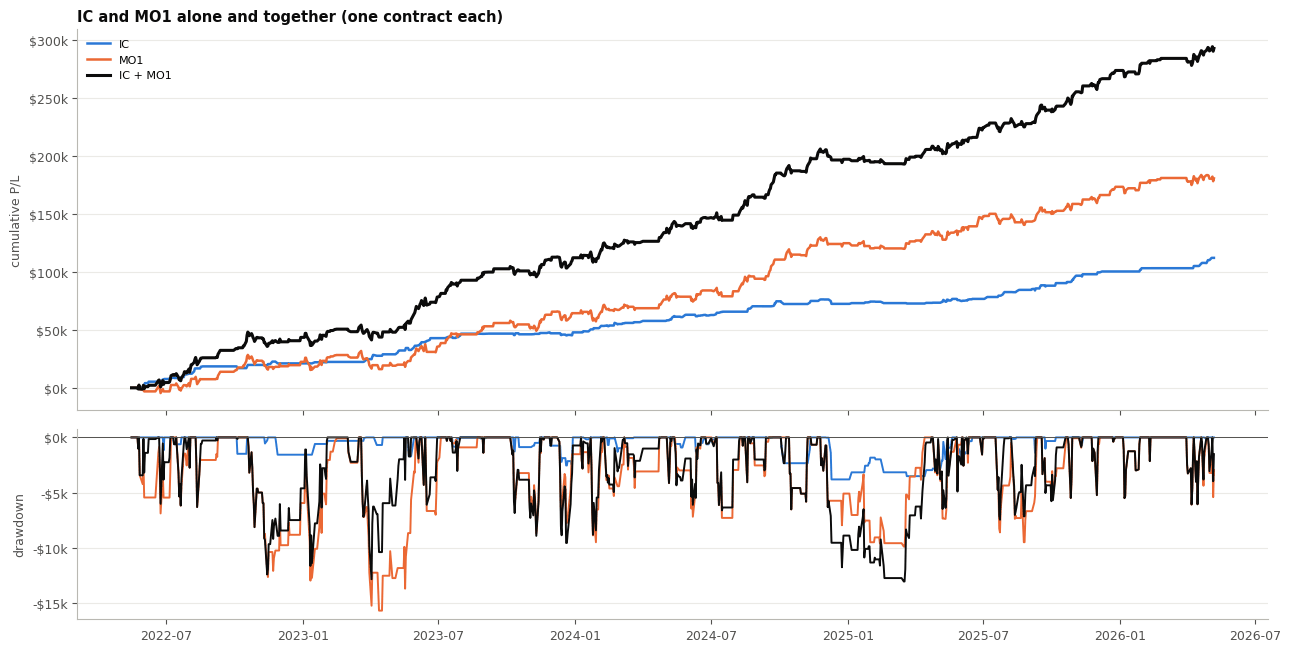

In [12]:
display(cm.combined_table(books))
cm.fig_combined(books); plt.show()

| book | capital | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | worst drawdown ends |
|---|---|---|---|---|---|---|
| IC | $200k | $112.0k | **2.60** | 2.44 / 2.92 | **-$3.8k** | 2024-12-10 |
| MO1 | $200k | $180.6k | 1.58 | 1.65 / 1.43 | -$15.7k | 2023-04-13 |
| MO2 | $200k | $186.4k | 1.86 | 2.20 / 1.15 | -$15.7k | 2023-04-13 |
| **IC + MO1** | $400k | $292.6k | 2.18 | 2.22 / 2.11 | -$13.1k | 2025-03-17 |
| **IC + MO2** | $400k | $298.4k | **2.51** | 2.77 / 1.98 | -$12.9k | 2023-04-03 |
| MO1 + MO2 | $400k | $367.0k | 1.76 | 1.97 / 1.35 | **-$31.4k** | 2023-04-13 |

- **Adding IC to an MO book lifts it a lot:** IC + MO2 scores 2.51 against MO2's 1.86, and its drawdown (-$12.9k) is smaller than MO2's own
  (-$15.7k) even though it runs both books. That is diversification: IC's good stretches cover part of MO's bad ones.
- **Adding MO to IC lowers IC's Sharpe** (2.60 -> 2.51 with MO2, 2.18 with MO1) but adds $186k of P/L. At one contract each MO is the bigger
  book: its swings dominate the pair, so the pair looks more like MO than like IC. Sized to equal risk the picture would differ.
- **MO1 + MO2 is no diversification at all:** the drawdowns land on the same days and simply add up (-$31.4k = two times -$15.7k),
  and the Sharpe (1.76) sits between the two.
- **How they "don't affect each other":** they're separate trades with separate entry rules, so neither changes the other's trades. What
  they share is the market: on the few days both are in, they rise and fall together (§5). Because those days are few, combining them
  smooths the equity curve instead of doubling the risk.

### All three as one portfolio

IC, MO1 and MO2 in one account, one contract each, $200k per strategy ($600k). The margin table checks how much margin the portfolio
ties up on its busiest days (every condor opened that day, since all of them are open together by the afternoon), and the last table
lists the portfolio's worst days.

In [13]:
display(cm.margin_table(books))
display(cm.worst_portfolio_days(books).round(0))

,capital,peak day margin,median margin on a trading day,peak as % of capital,days all of them trade
IC,200000.0,6025.0,2405.0,3.012500,187.0
MO1,200000.0,4950.0,3545.0,2.475000,458.0
MO2,200000.0,4950.0,3495.0,2.475000,350.0
IC + MO1,400000.0,8675.0,3720.0,2.168750,104.0
IC + MO2,400000.0,8675.0,3545.0,2.168750,76.0
MO1 + MO2,400000.0,9900.0,6415.0,2.475000,350.0
IC + MO1 + MO2,600000.0,12520.0,6240.0,2.086667,76.0


,IC,MO1,MO2,portfolio
date,,,,
2025-10-27,0.0,-4847.0,-4847.0,-9694.0
2025-08-25,0.0,-4672.0,-4672.0,-9344.0
2025-05-28,-1037.0,-3872.0,-3872.0,-8781.0
2025-01-23,0.0,-4377.0,-4377.0,-8754.0
2023-06-12,0.0,-4307.0,-4307.0,-8614.0
2024-05-06,0.0,-4142.0,-4142.0,-8284.0
2024-08-19,0.0,-4067.0,-4067.0,-8134.0
2026-04-13,0.0,-4022.0,-4022.0,-8044.0
2026-05-06,0.0,-3972.0,-3972.0,-7944.0


| portfolio | capital | total P/L | Sharpe | 2022-24 / 2025-26 | max drawdown | worst day |
|---|---|---|---|---|---|---|
| **IC alone** | $200k | $112.0k | **2.60** | 2.44 / 2.92 | **-$3.8k** | -$2.4k |
| IC + MO2 | $400k | $298.4k | 2.51 | 2.77 / 1.98 | -$12.9k | -$4.9k |
| IC + MO1 | $400k | $292.6k | 2.18 | 2.22 / 2.11 | -$13.1k | -$4.9k |
| IC + MO1 + MO2 | $600k | **$479.0k** | 2.12 | 2.30 / 1.77 | **-$28.1k** | **-$9.7k** |

**Adding the third book makes the portfolio worse, not better.**

- **All three earn the most money** ($479.0k), but Sharpe falls to 2.12 and the drawdown grows to -$28.1k, ending 2023-04-03, MO's bad
  stretch.
- **The reason is MO1 and MO2 together.** They're 0.88 correlated and trade the same trades on 350 days, so holding both is close to two
  contracts of one MO book: every MO loss counts twice. **On all ten of the portfolio's worst days MO1 and MO2 lose the same amount on
  the same day**, with IC flat on eight of them (the worst, 2025-10-27, is MO1 and MO2 -$4.8k each, -$9.7k in all).
- **IC + MO2 is the best combination with MO in it:** Sharpe 2.51 and a drawdown smaller than MO2 alone. MO2 is MO1 with a realized-
  volatility floor: it makes slightly more than MO1 ($186.4k against $180.6k) on fewer, better days.

**Margin isn't the limit at one contract each.** On the busiest day all three together tie up about $12.5k of margin (median $6.2k on a
trading day), about 2% of $600k. The three books are in on the same day on 76 sessions.

**A shared $200k would only make the numbers look better, not the portfolio.** Scored on one $200k instead of $600k, the three-book
Sharpe would read 2.47, but only because the same P/L is measured against less capital. The drawdown (-$28.1k) is the same, and on
$200k it is 14% of the account instead of 5%.

## 8. Summary

**Why IC and MO1 / MO2 aren't correlated, despite similar setups:**

1. **Same trade, different timing.** All three sell 10-wide 0DTE SPX condors, and when IC and MO1 open in the same minute their
   condors move together (0.77). The low correlation isn't about the trade.
2. **They trade on different days.** IC and MO1 share only 104 of their 187 and 458 trading days. Half of IC's daily swings but only 21% of
   MO1's fall on those shared days, so even though they move together on them (0.60), the overall daily correlation is
   0.60 x sqrt(0.50 x 0.21) = **0.20**.
3. **Because their signals point opposite ways.** IC enters when SPX is **at or below its open** (a pullback); MO enters when SPX is
   **at least 0.5% above its 5-day average** (a stretched rally). That alone rejects 74% of MO1's condors from IC's view. IC also trades
   only seven entry times, skips Thursdays and requires the VIX9D/VIX band, which MO doesn't. Only 73 of MO1's 458 days would pass every
   IC filter.
4. **Even on shared days they differ:** different minutes and different strikes (MO about 7 points from spot, IC about 10-13), so the
   same move can break MO's short strike and leave IC's intact.
5. **Their spikes differ because their winning zones sit on opposite sides of the day's open** (IC below, MO above), so up days hurt
   IC and pay MO while down days do the reverse; IC also avoids almost all the turbulent days MO trades (Section 6).

**What it means for running them together:**

- **They don't interfere:** separate entry rules mean neither book changes the other's trades.
- **They diversify:** their worst days rarely coincide, they never lost in the same quarter, and adding IC to MO2 lifts its Sharpe from
  1.86 to 2.51 and shrinks its drawdown.
- **IC alone has the best Sharpe** (2.60) and by far the smallest drawdown (-$3.8k); adding MO adds money ($186k with MO2) at a lower
  Sharpe, because at one contract each MO's bigger swings dominate.
- **MO1 and MO2 are effectively one book** (0.88): running both is close to doubling one position, not diversifying. All three together
  earn the most ($479.0k) but at a Sharpe of 2.12 with a -$28.1k drawdown.

**Caveats.**

- IC is a rebuild of the strategy with the backtester's rules (see `ic_analysis.ipynb`); MO1 and MO2 are the backtester's own logs.
- The comparison covers 2022-05 to 2026-05 only (the IC export's range).
- Correlation is measured on daily P/L as the backtester does. Within a day, the books' open positions overlap more than the daily
  number suggests on the days they share (§5).